# Cinemática inversa · de posición a ángulos

[Explicación completa y diagramas](README.md) · [Mapa de estudio](../README.md)

Notebook autocontenido: se ejecuta de arriba hacia abajo y no importa funciones de `code/`. Las ecuaciones se implementan aquí para poder leerlas. Las salidas guardadas muestran simulación del modelo rígido nominal; no son mediciones del prototipo.

**Convenciones:** base fija, metros, radianes y vectores columna. Las longitudes se toman de la tabla 2 de Ramzy et al. (2024); los métodos siguen las semanas 4–9 del curso. [Fuentes y alcance](../../docs/paper.md).

## 1. La pregunta inversa

Ahora se conoce la posición deseada y se buscan ángulos. Se utiliza el mismo ejemplo de la directa para poder reconstruirlo. No se exige recuperar una única configuración: varios ángulos pueden producir la misma posición.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
l1, l2, l3 = 0.04, 0.29, 0.24  # metros, tabla 2 del paper

def position(q):
    q1, q2, q3 = q
    rho = l2 * np.cos(q2) + l3 * np.cos(q2 + q3)
    height = l2 * np.sin(q2) + l3 * np.sin(q2 + q3)
    return np.array([np.cos(q1) * rho, np.sin(q1) * rho, l1 + height])

q_reference = np.deg2rad([30, 40, -50])
target = position(q_reference)
print("Objetivo (m):", target)

Objetivo (m): [0.397078 0.229253 0.184733]


## 2. Reducir el problema a un triángulo

$$r=\sqrt{x^2+y^2},\quad h=z-l_1,\quad D=\sqrt{r^2+h^2}.$$

`r` es una distancia positiva. `h` descuenta el pedestal: utilizar `z` directamente cambia el triángulo. En la rama de base principal, $q_1=\operatorname{atan2}(y,x)$.

Debe cumplirse $|l_2-l_3|\leq D\leq l_2+l_3$. Fuera de ese anillo no existe solución nominal, aunque el objetivo parezca cercano a la base.

In [2]:
x, y, z = target
radius = np.hypot(x, y)
height = z - l1
distance = np.hypot(radius, height)
print("Radio, altura relativa y distancia:", radius, height, distance)
print("Intervalo alcanzable de D:", abs(l2 - l3), l2 + l3)
assert abs(l2 - l3) <= distance <= l2 + l3

Radio, altura relativa y distancia: 0.4585067492274335 0.1447328441690331 0.4808076905253973
Intervalo alcanzable de D: 0.04999999999999999 0.53


## 3. Ley de cosenos y dos ramas

$$C_3=\frac{D^2-l_2^2-l_3^2}{2l_2l_3},\quad S_3=\pm\sqrt{1-C_3^2},$$
$$q_3=\operatorname{atan2}(S_3,C_3),\qquad q_2=\operatorname{atan2}(h,r)-\operatorname{atan2}(l_3S_3,l_2+l_3C_3).$$

El signo de `s3` elige un codo. `atan2` conserva el cuadrante usando dos componentes. El codo articular vale cero al extenderse; no es el ángulo interior suplementario del triángulo.

La función devuelve dos candidatos. En la frontera pueden coincidir; el módulo de producción elimina duplicados. En el eje de base se elige `q1=0` como representante, sin afirmar unicidad. Sólo se estudia la familia con radio positivo.

In [3]:
def inverse_position(target):
    x, y, z = target
    radius = np.hypot(x, y)
    height = z - l1
    c3 = (radius**2 + height**2 - l2**2 - l3**2) / (2 * l2 * l3)
    if abs(c3) > 1 + 1e-12:
        return []  # no existe un triángulo con esas longitudes
    c3 = np.clip(c3, -1, 1)  # sólo corrige redondeo en la frontera
    q1 = np.arctan2(y, x) if radius > 1e-12 else 0.0
    solutions = []
    for sign in [1, -1]:
        s3 = sign * np.sqrt(1 - c3**2)
        q3 = np.arctan2(s3, c3)
        q2 = np.arctan2(height, radius) - np.arctan2(l3 * s3, l2 + l3 * c3)
        solutions.append(np.array([q1, q2, q3]))
    return solutions

solutions = inverse_position(target)
for number, candidate in enumerate(solutions, start=1):
    print("Rama", number, "(grados):", np.rad2deg(candidate))

Rama 1 (grados): [30.       -4.962218 50.      ]
Rama 2 (grados): [ 30.  40. -50.]


## 4. Cerrar el recorrido con la directa

Cada candidato se sustituye en `position`. El residuo es la distancia entre la posición reconstruida y el objetivo. No es la diferencia entre ángulos: una solución distinta puede ser correcta.

In [4]:
for candidate in solutions:
    residual = np.linalg.norm(position(candidate) - target)
    print("Residuo (m):", residual)
    assert residual < 1e-12
assert len(solutions) == 2
assert inverse_position([1, 0, l1]) == []
assert inverse_position([0, 0, l1]) == []  # hueco interior: l2 y l3 son distintos
print("También se rechazan objetivos demasiado lejos y dentro del hueco interior.")

Residuo (m): 2.7755575615628914e-17
Residuo (m): 2.7755575615628914e-17
También se rechazan objetivos demasiado lejos y dentro del hueco interior.


## 5. Ver las dos configuraciones

Ambos brazos deben terminar en el mismo punto. Se dibuja el plano radial de la rama principal para distinguir la postura del codo con claridad.

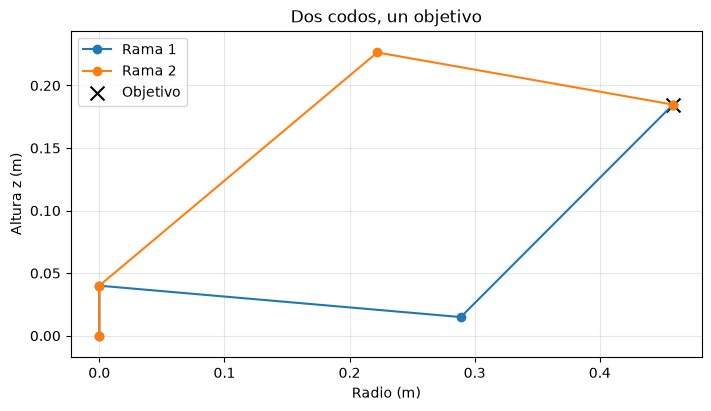

In [5]:
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for number, candidate in enumerate(solutions, start=1):
    q1, q2, q3 = candidate
    radial_points = [0, 0, l2 * np.cos(q2), radius]
    heights = [0, l1, l1 + l2 * np.sin(q2), target[2]]
    ax.plot(radial_points, heights, "o-", label=f"Rama {number}")
ax.scatter([radius], [target[2]], marker="x", s=100, color="black", label="Objetivo")
ax.set(xlabel="Radio (m)", ylabel="Altura z (m)", title="Dos codos, un objetivo")
ax.axis("equal")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Lectura y ejercicio

Una rama recupera aproximadamente `[30,40,-50]` grados. La otra cambia hombro y codo manteniendo el extremo. Esto no demuestra que ambas posturas sean físicamente admisibles: faltan límites mecánicos y colisiones.

Probar `[0.53,0,0.04]`: las ramas se juntan en la extensión. Probar `[0,0,0.30]`: la posición ya no determina el ángulo de base. **Siguiente:** estudiar velocidades mediante [cinemática diferencial](../differential-kinematics/README.md).